In [1]:
%load_ext autoreload
%autoreload 2

## IMPORTS
import os

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import seaborn as sns

import src.data_filepaths as data_filepaths
import src.utils.loaders as loaders
import src.utils.vis.colors_utils as colors_utils
from src.utils.df_tools import map_values_b_to_bp
from src.utils.loaders import process_loaded_building_df
from src.utils.vis.map import CategoricalColorMap, MapExplorer

# configs
sns.set_theme()

# Buildings Exploration

Headline statistics

* 237833 buildings total

In [2]:
## LOAD
# print(os.getcwd())

# here for testing
buildings = gpd.read_parquet(data_filepaths.OVERTURE_BUILDING)
b_gdf = buildings.to_crs("EPSG:3414")
b_gdf = b_gdf.set_index("id")

print(b_gdf.columns)
print(b_gdf.dtypes)
b_gdf.head()

# print(b_gdf["sources"].iloc[0][0])

Index(['names', 'sources', 'level', 'height', 'min_height', 'is_underground',
       'num_floors', 'num_floors_underground', 'min_floor', 'subtype', 'class',
       'facade_color', 'facade_material', 'roof_material', 'roof_shape',
       'roof_direction', 'roof_orientation', 'roof_color', 'roof_height',
       'geometry', 'has_parts', 'version', 'bbox', 'theme', 'type'],
      dtype='str')
names                       object
sources                     object
level                      float64
height                     float64
min_height                 float64
is_underground                bool
num_floors                 float64
num_floors_underground     float64
min_floor                  float64
subtype                        str
class                          str
facade_color                   str
facade_material                str
roof_material                  str
roof_shape                     str
roof_direction             float64
roof_orientation               str
roof_color  

,names,sources,level,height,min_height,is_underground,num_floors,num_floors_underground,min_floor,subtype,...,roof_direction,roof_orientation,roof_color,roof_height,geometry,has_parts,version,bbox,theme,type
id,,,,,,,,,,,,,,,,,,,,,
e71fc534-b314-449f-9ec9-1e93ab103733,None,"[{'property': '', 'dataset': 'Microsoft ML Bui...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((5872.709 22340.088, 5882.848 22339.7...",False,3,"{'xmin': 103.6344985961914, 'xmax': 103.634597...",buildings,building
af894262-c019-4f4d-9b7c-71c934d25f9e,None,"[{'property': '', 'dataset': 'Google Open Buil...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((6072.91 21627.47, 6076.606 21639.501...",False,1,"{'xmin': 103.63619995117188, 'xmax': 103.63633...",buildings,building
4a403634-2a1c-470d-8272-ed1283c02a6c,None,"[{'property': '', 'dataset': 'Google Open Buil...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((6079.655 21624.617, 6083.183 21628.7...",False,1,"{'xmin': 103.6363296508789, 'xmax': 103.636405...",buildings,building
0c34c5e2-67c0-4593-ba6d-90a5f838fe8a,None,"[{'property': '', 'dataset': 'Google Open Buil...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((6098.474 21619.109, 6100.055 21625.3...",False,1,"{'xmin': 103.63646697998047, 'xmax': 103.63655...",buildings,building
0a85c6b1-0f74-4cb2-9a27-30b12e3a9ab7,None,"[{'property': '', 'dataset': 'Google Open Buil...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((6099.522 21635.651, 6100.268 21638.1...",False,1,"{'xmin': 103.636474609375, 'xmax': 103.6365585...",buildings,building


In [3]:
# basic parameters
b_gdf["area_m2"] = b_gdf.area
b_gdf["perimeter_m"] = b_gdf.length
b_gdf["centroid"] = b_gdf.centroid

b_gdf["src_dataset_label"] = b_gdf["sources"].map(
    lambda x: x[0]["dataset"]
)  # extract dataset label

print(b_gdf["height"].value_counts())
print(b_gdf["num_floors"].value_counts())
print(b_gdf["has_parts"].value_counts())
print(b_gdf["type"].value_counts())

# [] make histogram instead lmao

height
10.00     914
15.00     268
12.00     168
18.00      88
20.00      67
         ... 
207.00      1
33.15       1
19.70       1
15.50       1
4.30        1
Name: count, Length: 189, dtype: int64
num_floors
2.0     7476
3.0     4881
1.0     3299
4.0     2667
12.0    1909
5.0     1286
16.0    1046
13.0     925
10.0     741
14.0     642
15.0     628
11.0     616
6.0      599
17.0     536
7.0      440
8.0      426
18.0     385
9.0      313
25.0     308
20.0     256
30.0     155
19.0     152
22.0     112
24.0     103
40.0      92
21.0      90
36.0      65
26.0      65
23.0      64
28.0      51
27.0      36
32.0      32
38.0      26
31.0      26
29.0      22
34.0      19
35.0      17
33.0      16
47.0      16
37.0      12
39.0      11
50.0      11
45.0      10
42.0       6
48.0       6
43.0       4
46.0       4
44.0       3
55.0       3
56.0       2
49.0       1
52.0       1
54.0       1
41.0       1
66.0       1
70.0       1
63.0       1
57.0       1
Name: count, dtype: int64
has_parts

In [4]:
print(b_gdf["subtype"].unique())
print(b_gdf["class"].unique())

<ArrowStringArray>
[             nan,     'industrial',     'commercial', 'transportation',
    'residential',          'civic',    'outbuilding',        'service',
      'education',  'entertainment',      'religious',        'medical',
   'agricultural',       'military']
Length: 14, dtype: str
<ArrowStringArray>
[                 nan,         'industrial',             'office',
            'parking',          'dormitory',     'transportation',
        'residential',         'commercial',          'warehouse',
      'train_station',               'roof',            'service',
             'retail',        'manufacture',                'hut',
       'storage_tank',       'fire_station',               'shed',
          'boathouse',             'garage',         'university',
         'grandstand',             'public',             'hangar',
           'pavilion',             'church',         'guardhouse',
         'apartments',            'terrace', 'semidetached_house',
             

### Area

Max area at 99.9th percentile: 20404.78 m^2


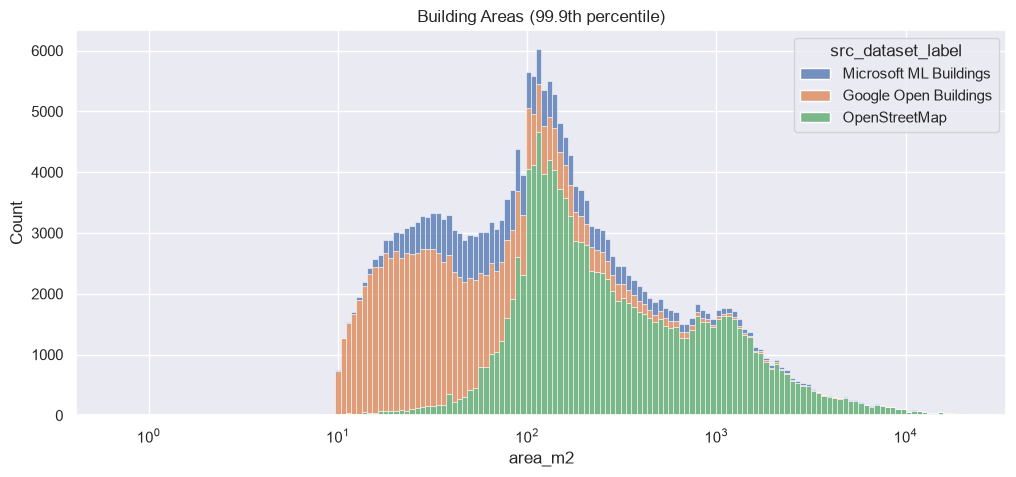

In [5]:
def plot_visualization_building_area():
    areas = b_gdf["area_m2"]

    percentile_threshold = 99.9
    max_area = np.percentile(areas, percentile_threshold)
    print(f"Max area at {percentile_threshold}th percentile: {max_area:.2f} m^2")

    # PLOTTING
    fig, ax = plt.subplots(1, 1, figsize=(12, 5))

    ax.set_title(f"Building Areas ({percentile_threshold}th percentile)")

    sns.histplot(
        b_gdf[areas < max_area],
        x="area_m2",
        ax=ax,
        hue="src_dataset_label",
        multiple="stack",
        log_scale=True,
    )


plot_visualization_building_area()

# Pre-Process: Building Removal

In [6]:
bp_gdf = process_loaded_building_df(gpd.read_parquet(data_filepaths.OVERTURE_BUILDING_PART))

## Zonal Removal

To remove:

* OSM
  * `landuse=construction`
  * `landuse=industrial_port`
* Masterplan

In [7]:
osm_landuse_gdf = loaders.load_osm_landuse_1_geojson_to_gdf(data_filepaths.OSM_landuse)
mp_landuse_gdf = loaders.load_masterplan_landuse_geojson_to_gdf(data_filepaths.MASTERPLAN_LANDUSE)

In [8]:
buildings_osm_merge = gpd.sjoin(
    b_gdf[["centroid"]].set_geometry("centroid"),
    osm_landuse_gdf,
    how="left",
    predicate="intersects",
)
# deduplicate
buildings_osm_merge = buildings_osm_merge[
    ~buildings_osm_merge.index.duplicated(keep="first")
]

buildings_osm_merge = buildings_osm_merge.drop(columns="index_right")

In [9]:
buildings_mp_merge = gpd.sjoin(
    b_gdf[["centroid"]].set_geometry("centroid"),
    mp_landuse_gdf,
    how="left",
    predicate="intersects",
)
# deduplicate
buildings_mp_merge = buildings_mp_merge[
    ~buildings_mp_merge.index.duplicated(keep="first")
]

buildings_mp_merge["landuse"].value_counts(dropna=False)

landuse
RESIDENTIAL                                  120330
BUSINESS 2                                    44653
RESERVE SITE                                   7725
SPECIAL USE                                    6226
COMMERCIAL                                     6095
ROAD                                           6075
EDUCATIONAL INSTITUTION                        6000
PORT / AIRPORT                                 4713
UTILITY                                        4190
PARK                                           4136
OPEN SPACE                                     3727
RESIDENTIAL WITH COMMERCIAL AT 1ST STOREY      2850
SPORTS & RECREATION                            2654
CIVIC & COMMUNITY INSTITUTION                  2651
BUSINESS 1                                     2611
AGRICULTURE                                    2573
COMMERCIAL & RESIDENTIAL                       2507
TRANSPORT FACILITIES                           1377
PLACE OF WORSHIP                               1312
WHIT

In [10]:
def visualize_mp_landuse_buildings():
    """
    Oh lord this is actually beautiful
    """
    temp_b_gdf = b_gdf.copy()
    temp_bp_gdf = bp_gdf.copy()

    temp_b_gdf[["mp_landuse", "mp_gpr"]] = buildings_mp_merge[["landuse", "gpr"]]

    map_values_b_to_bp(temp_b_gdf, temp_bp_gdf, "mp_landuse", "mp_landuse")

    mp_lu_color_mapping = colors_utils.DEFAULT_MASTERPLAN_LANDUSE_COLORS

    cmap = CategoricalColorMap(
        cat_colors=list(mp_lu_color_mapping.values()),
        cat_labels=list(mp_lu_color_mapping.keys()),
        nan_color=np.array([0.2, 0.2, 0.2, 0.5]),
    )

    mapper = MapExplorer(
        temp_b_gdf,
        temp_bp_gdf,
        # enable_debug_mode=True,
    )
    return mapper.build_singleprop(
        "mp_landuse", cmap, title="Masterplan Landuse mapped onto Buildings"
    )


visualize_mp_landuse_buildings()

## Size/Source Removal

Per source:
* OSM
* Google
  * there are at least two planes, at 250 and 285 m^2
* Microsoft

## Combine and Visualize

In [17]:
def full_removal_combine_and_vis(
    b_gdf: gpd.GeoDataFrame,
    bp_gdf: gpd.GeoDataFrame,
    buildings_osm_merge,  # [landuse]
    buildings_mp_merge,  # [landuse, gpr]
    mp_landuse_gdf,
):
    """
    Adds removal reasons to b_gdf, and maps to bp_gdf as well.

    Creates new columns `removal_reason`, `is_removed`
    """

    SIZE_THRESHOLDS = {
        "OSM": 70,  # this number is quite high, but for demand I think it's fine
        "Google": 400,
        "Microsoft": 400,
    }
    MP_COVERAGE_THRESHOLD = 0.05
    b_gdf = b_gdf.copy()
    bp_gdf = bp_gdf.copy()

    # clean removals that have no other condition
    mp_landuses_remove = [
        "HEALTH & MEDICAL CARE",
        "EDUCATIONAL INSTITUTION",
        "PLACE OF WORSHIP",
        "CIVIC & COMMUNITY INSTITUTION",
        # "OPEN SPACE",
        "PARK",
        "BEACH AREA",
        "SPORTS & RECREATION",
        "WATERBODY",
        "ROAD",
        "TRANSPORT FACILITIES",
        "MASS RAPID TRANSIT",
        "LIGHT RAPID TRANSIT",
        "UTILITY",
        "CEMETERY",
        "PORT / AIRPORT",
        # "RESERVE SITE",
        "SPECIAL USE",
    ]
    MP_LANDUSE_REMOVAL_DICT = {landuse: "Landuse-MP" for landuse in mp_landuses_remove}

    b_gdf[["mp_landuse"]] = buildings_mp_merge[["landuse"]]
    b_gdf[["mp_gpr"]] = buildings_mp_merge[["gpr"]]
    b_gdf[["mp_OBJECTID"]] = buildings_mp_merge[["OBJECTID"]]

    # first calculate areas of a zone
    # this makes an assumption that building footprints are fully inside their zone
    # which is not true. but I can't be bothered
    b_mp_covered = b_gdf.groupby("mp_OBJECTID")["area_m2"].sum()
    mp_area = mp_landuse_gdf.geometry.area

    b_mp_coverage_prop = b_gdf["mp_OBJECTID"].map(b_mp_covered / mp_area)

    ###################################

    # now asasign all reasons at once
    b_gdf["removal_reason"] = np.select(
        [
            (buildings_osm_merge["landuse"] == "construction")
            | (buildings_osm_merge["landuse"] == "industrial_port"),
            (b_gdf["src_dataset_label"] == "OpenStreetMap")
            & (b_gdf["area_m2"] < SIZE_THRESHOLDS["OSM"]),
            (b_gdf["src_dataset_label"] == "Google Open Buildings")
            & (b_gdf["area_m2"] < SIZE_THRESHOLDS["Google"]),
            (b_gdf["src_dataset_label"] == "Microsoft ML Buildings")
            & (b_gdf["area_m2"] < SIZE_THRESHOLDS["Microsoft"]),
            buildings_mp_merge["landuse"].isna(),  # remove NaNs here, about 130 of them
            b_mp_coverage_prop < MP_COVERAGE_THRESHOLD,
        ],
        [
            "Landuse-OSM",
            "Size-OSM",
            "Size-Google",
            "Size-Microsoft",
            "Landuse-MP",
            "Landuse-MP_coverage",
        ],
        default=None,
    )

    # apply without overwriting non-matches
    b_gdf["removal_reason"] = (
        buildings_mp_merge["landuse"]
        .map(MP_LANDUSE_REMOVAL_DICT)
        .fillna(b_gdf["removal_reason"])
    )

    map_values_b_to_bp(b_gdf, bp_gdf, "removal_reason", "removal_reason")

    # create boolean removed columns
    b_gdf["is_removed"] = ~b_gdf["removal_reason"].isna()
    bp_gdf["is_removed"] = ~bp_gdf["removal_reason"].isna()

    print(b_gdf["removal_reason"].value_counts(dropna=False))

    # sns.catplot(data=b_gdf, x="removal_reason", kind="count")

    title = (
        f"Removal thresholds: OSM {SIZE_THRESHOLDS["OSM"]}"
        + f"; Google {SIZE_THRESHOLDS["Google"]}"
        + f"; Microsoft {SIZE_THRESHOLDS["Microsoft"]}"
    )

    # return

    mapper = MapExplorer(
        b_gdf,
        bp_gdf,
        # enable_debug_mode=True,
    )
    return mapper.build_configurable(["removal_reason"], title=title)


full_removal_combine_and_vis(
    b_gdf, bp_gdf, buildings_osm_merge, buildings_mp_merge, mp_landuse_gdf
)

removal_reason
NaN                    108252
Size-Google             56897
Landuse-MP              41003
Size-Microsoft          19362
Size-OSM                 5748
Landuse-OSM              4742
Landuse-MP_coverage      1829
Name: count, dtype: int64


# Pre-Process: Zone Removals

In [ ]:
# b_rmv = b_gdf[b_gdf["removal_reason"].isna()]
# bp_rmv = bp_gdf[bp_gdf["removal_reason"].isna()]

KeyError: 'removal_reason'